In [1]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split

# Configuration
INPUT_FILE = "../datasets/Data_train.json"
OUTPUT_DIR = Path("../datasets")
RANDOM_STATE = 42

def clean_category(cat):
    """Ramène chaque type à sa catégorie principale (sert à stratifier)."""
    if not cat:
        return "sans type"
    c = cat.split(" -")[0].split(" après")[0].strip().lower()
    if c.startswith("fin") or c == "partie complète":
        c = "fin"
    return c

# 1. Charger les données
with open(INPUT_FILE, "r", encoding="utf-8") as f:
    data = json.load(f)

examples = data["examples"]
labels = [clean_category(e.get("type")) for e in examples]
print(f"Nombre total d'exemples : {len(examples)}")
print(Counter(labels))

# 2. Séparer 20 % pour le test (stratifié)
train_val, test, labels_tv, labels_test = train_test_split(
    examples, labels,
    test_size=0.20,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=labels
)

# 3. Séparer train / validation (stratifié)
# 12,5 % de 80 % = 10 % du dataset total
train, validation, labels_train, labels_val = train_test_split(
    train_val, labels_tv,
    test_size=0.125,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=labels_tv
)

# 4. Créer le dossier de sortie
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 5. Enregistrer les trois ensembles
datasets = {
    "train": train,
    "validation": validation,
    "test": test
}

for name, dataset in datasets.items():
    output_file = OUTPUT_DIR / f"{name}.json"

    output_data = {
        "format": data.get("format", ""),
        "description": data.get("description", ""),
        "examples": dataset
    }

    with open(output_file, "w", encoding="utf-8") as f:
        json.dump(output_data, f, ensure_ascii=False, indent=2)

    print(f"{name}: {len(dataset)} exemples -> {output_file}")

print("Répartition terminée.")

# 6. Vérification de la stratification
for name, labs in [("train", labels_train), ("validation", labels_val), ("test", labels_test)]:
    c = Counter(labs)
    print(f"\n{name.upper()} ({len(labs)} ex.)")
    print({k: f"{100 * v / len(labs):.0f}%" for k, v in c.most_common()})

Nombre total d'exemples : 445
Counter({'action.valide': 155, 'exploration': 69, 'action.incohérente': 63, 'action.invalide': 62, 'fin': 36, 'action.ambiguë': 31, 'énonciation': 20, 'début': 9})
train: 311 exemples -> ..\datasets\train.json
validation: 45 exemples -> ..\datasets\validation.json
test: 89 exemples -> ..\datasets\test.json
Répartition terminée.

TRAIN (311 ex.)
{'action.valide': '35%', 'exploration': '15%', 'action.invalide': '14%', 'action.incohérente': '14%', 'fin': '8%', 'action.ambiguë': '7%', 'énonciation': '5%', 'début': '2%'}

VALIDATION (45 ex.)
{'action.valide': '36%', 'exploration': '16%', 'action.incohérente': '13%', 'action.invalide': '13%', 'fin': '9%', 'action.ambiguë': '7%', 'énonciation': '4%', 'début': '2%'}

TEST (89 ex.)
{'action.valide': '35%', 'exploration': '16%', 'action.incohérente': '15%', 'action.invalide': '13%', 'fin': '8%', 'action.ambiguë': '7%', 'énonciation': '4%', 'début': '2%'}


Le script crée un dossier `datasets/` contenant `train.json`, `validation.json` et `test.json`.

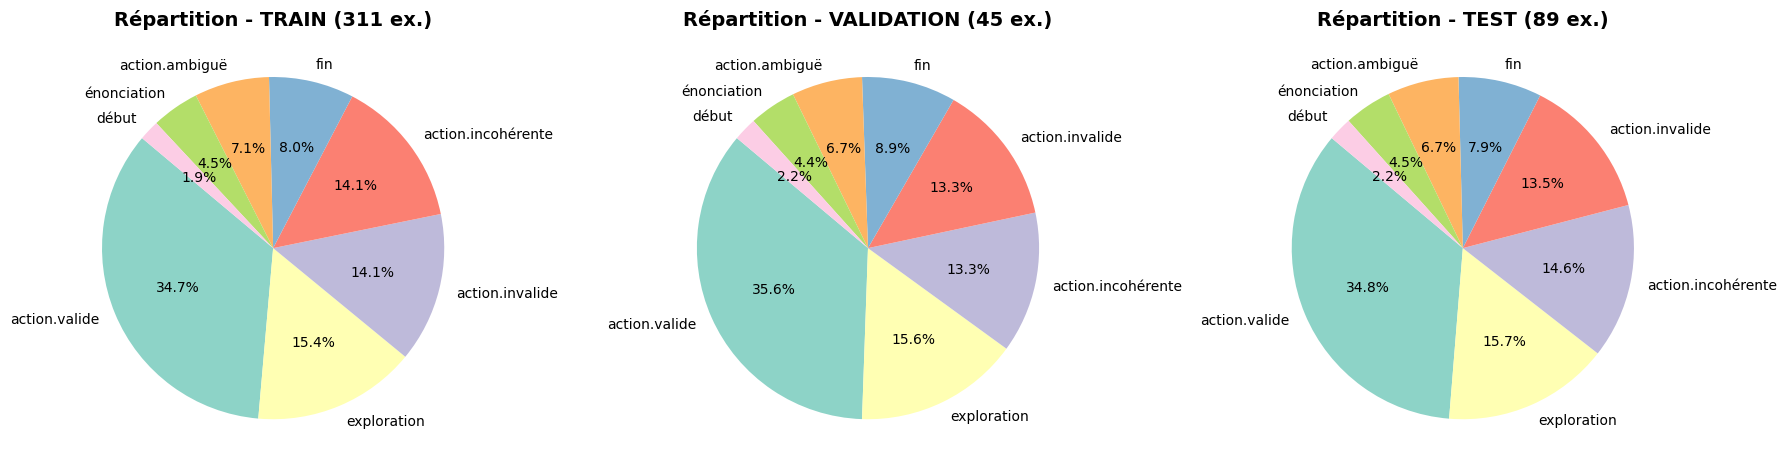

In [3]:
import matplotlib.pyplot as plt
# Configuration de la figure matplotlib avec 3 sous-graphiques (1 ligne, 3 colonnes)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, (name, dataset) in enumerate(datasets.items()):
    # Nettoyage et comptage
    categories = [clean_category(item.get("type", "sans type")) for item in dataset]
    counter = Counter(categories)

    # Tri des données pour un affichage propre
    labels, values = zip(*counter.most_common())

    # Création du camembert pour l'ensemble courant
    axes[i].pie(
        values,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=plt.cm.Set3.colors
    )
    axes[i].set_title(f"Répartition - {name.upper()} ({len(dataset)} ex.)", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [4]:
for name, dataset in datasets.items():
    print(f"\n{name.upper()} — {len(dataset)} exemples")
    categories = [clean_category(item.get("type", "sans type")) for item in dataset]
    counter = Counter(categories)
    for category, count in counter.most_common():
        percentage = (count / len(dataset)) * 100
        print(f"  - {category}: {count} ({percentage:.1f}%)")



TRAIN — 311 exemples
  - action.valide: 108 (34.7%)
  - exploration: 48 (15.4%)
  - action.invalide: 44 (14.1%)
  - action.incohérente: 44 (14.1%)
  - fin: 25 (8.0%)
  - action.ambiguë: 22 (7.1%)
  - énonciation: 14 (4.5%)
  - début: 6 (1.9%)

VALIDATION — 45 exemples
  - action.valide: 16 (35.6%)
  - exploration: 7 (15.6%)
  - action.incohérente: 6 (13.3%)
  - action.invalide: 6 (13.3%)
  - fin: 4 (8.9%)
  - action.ambiguë: 3 (6.7%)
  - énonciation: 2 (4.4%)
  - début: 1 (2.2%)

TEST — 89 exemples
  - action.valide: 31 (34.8%)
  - exploration: 14 (15.7%)
  - action.incohérente: 13 (14.6%)
  - action.invalide: 12 (13.5%)
  - fin: 7 (7.9%)
  - action.ambiguë: 6 (6.7%)
  - énonciation: 4 (4.5%)
  - début: 2 (2.2%)


On peut voir la répartition des exemples en foction de leurs types dans chacun des 3 ensembles.